# 01 — Dados e EDA: cancelamento de reservas de hotel

**Pergunta:** no momento em que a reserva é feita, dá para saber quais vão ser canceladas?

**Dados:** 119.390 reservas de dois hotéis em Portugal (City Hotel e Resort Hotel), chegadas de jul/2015 a ago/2017.
Fonte: Antonio, Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22. Baixado do Kaggle (`jessemostipak/hotel-booking-demand`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_rows", 50)

df = pd.read_csv("../data/raw/hotel_bookings.csv")
df.shape

(119390, 32)

## Etapa 1 — Conhecer e limpar os dados

### 1.1 Visão geral das colunas

Para cada coluna: tipo, quantos nulos, quantos valores diferentes e um exemplo de valor.

In [2]:
resumo = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores distintos": df.nunique(),
    "exemplo": df.apply(lambda col: col.dropna().iloc[0]),
})
resumo

,tipo,nulos,% nulos,valores distintos,exemplo
hotel,str,0,0.0,2,Resort Hotel
is_canceled,int64,0,0.0,2,0
lead_time,int64,0,0.0,479,342
arrival_date_year,int64,0,0.0,3,2015
arrival_date_month,str,0,0.0,12,July
arrival_date_week_number,int64,0,0.0,53,27
arrival_date_day_of_month,int64,0,0.0,31,1
stays_in_weekend_nights,int64,0,0.0,17,0
stays_in_week_nights,int64,0,0.0,35,0
adults,int64,0,0.0,14,2


### 1.2 O que cada coluna significa

Resumo do dicionário de dados do artigo original.

| Coluna | Significado |
|---|---|
| `hotel` | City Hotel (Lisboa) ou Resort Hotel (Algarve) |
| `is_canceled` | **Alvo.** 1 = reserva cancelada, 0 = não cancelada |
| `lead_time` | Dias entre a data em que a reserva foi feita e a data de chegada |
| `arrival_date_year`, `_month`, `_week_number`, `_day_of_month` | Data de chegada |
| `stays_in_weekend_nights` | Noites de fim de semana (sáb/dom) reservadas |
| `stays_in_week_nights` | Noites de semana (seg–sex) reservadas |
| `adults`, `children`, `babies` | Número de hóspedes por faixa |
| `meal` | Refeição: BB = café da manhã, HB = meia pensão, FB = pensão completa, SC/Undefined = sem refeição |
| `country` | País de origem do hóspede (código de 3 letras) |
| `market_segment` | Segmento de mercado (TA = agência de viagem, TO = operadora) |
| `distribution_channel` | Canal pelo qual a reserva chegou |
| `is_repeated_guest` | 1 = hóspede que já se hospedou antes |
| `previous_cancellations` | Reservas anteriores do cliente que foram canceladas |
| `previous_bookings_not_canceled` | Reservas anteriores do cliente que não foram canceladas |
| `reserved_room_type` | Tipo de quarto reservado (código anonimizado) |
| `assigned_room_type` | Tipo de quarto atribuído ao hóspede — pode diferir do reservado |
| `booking_changes` | Alterações feitas na reserva até o check-in ou o cancelamento |
| `deposit_type` | No Deposit, Non Refund (depósito do valor total, sem reembolso) ou Refundable (depósito parcial) |
| `agent` | ID da agência de viagem que fez a reserva |
| `company` | ID da empresa que fez a reserva ou que paga por ela |
| `days_in_waiting_list` | Dias na lista de espera até a reserva ser confirmada |
| `customer_type` | Transient (avulsa), Transient-Party (avulsa ligada a outra), Contract, Group |
| `adr` | Diária média: valor total da hospedagem ÷ número de noites |
| `required_car_parking_spaces` | Vagas de estacionamento pedidas |
| `total_of_special_requests` | Pedidos especiais (ex.: cama de casal, andar alto) |
| `reservation_status` | Último status: Canceled, Check-Out ou No-Show |
| `reservation_status_date` | Data do último status |

### 1.3 O que a visão geral mostra

**Nulos.** Só 4 colunas têm nulos, e nem todo nulo é "dado faltando":
- `company` (94% nulo) e `agent` (14% nulo): no arquivo original o valor é `NULL`, que significa *não se aplica* — a reserva não foi feita por empresa ou por agência. Não é falha de preenchimento.
- `country` (488 linhas, 0,4%): país não informado.
- `children` (4 linhas): dado faltando de fato.

**Tipos para ajustar na limpeza:**
- `agent` e `company` estão como número, mas são IDs — devem ser tratados como categoria.
- `children` virou decimal (`float`) só por causa dos 4 nulos.
- A data de chegada está espalhada em 4 colunas, com o mês em texto — vale montar uma coluna de data só.
- `reservation_status_date` está como texto.
- Em `meal`, `SC` e `Undefined` significam a mesma coisa (sem refeição).

### 1.4 Tratar nulos e tipos

Decisões, com base no que a visão geral mostrou:
- `agent` e `company`: nulo vira `"sem agência"` / `"sem empresa"`, e o ID passa a ser texto (é categoria, não número).
- `children`: os 4 nulos viram 0 e a coluna volta a ser inteira.
- `country`: nulo vira `"desconhecido"`.
- `meal`: `Undefined` vira `SC` (as duas significam sem refeição).
- Data de chegada: as colunas de ano, mês e dia viram uma coluna `arrival_date`. As originais ficam por enquanto, para a EDA.
- `reservation_status_date`: texto vira data.

In [3]:
df["agent"] = df["agent"].astype("Int64").astype("string").fillna("sem agência")
df["company"] = df["company"].astype("Int64").astype("string").fillna("sem empresa")
df["children"] = df["children"].fillna(0).astype(int)
df["country"] = df["country"].fillna("desconhecido")
df["meal"] = df["meal"].replace("Undefined", "SC")

df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-"
    + df["arrival_date_month"] + "-"
    + df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d",
)
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"])

Conferindo: nenhum nulo sobrando, o período das datas e os tipos novos.

In [4]:
print("Nulos restantes:", df.isna().sum().sum())
print("Chegadas:", df["arrival_date"].min().date(), "a", df["arrival_date"].max().date())
print("Último status:", df["reservation_status_date"].min().date(), "a", df["reservation_status_date"].max().date())

df[["agent", "company", "children", "country", "meal", "arrival_date", "reservation_status_date"]].dtypes

Nulos restantes: 0
Chegadas: 2015-07-01 a 2017-08-31
Último status: 2014-10-17 a 2017-09-14


agent                              string
company                            string
children                            int64
country                               str
meal                                  str
arrival_date               datetime64[us]
reservation_status_date    datetime64[us]
dtype: object

Sem nulos. As chegadas vão de 01/07/2015 a 31/08/2017. O último status começa antes (out/2014) porque há cancelamentos feitos meses antes da data de chegada.

### 1.5 Valores estranhos

Três pontos para olhar: a diária (`adr`), o número de hóspedes e o número de noites. Primeiro só olhamos; a decisão vem depois.

In [5]:
df["guests"] = df["adults"] + df["children"] + df["babies"]
df["nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

colunas_ver = ["hotel", "is_canceled", "lead_time", "adults", "children", "babies",
               "nights", "market_segment", "adr", "reservation_status"]

**Diária (`adr`).** Distribuição, os casos extremos e as diárias zeradas por segmento.

In [6]:
display(df["adr"].describe(percentiles=[0.01, 0.5, 0.99]).round(2))
display(df.loc[(df["adr"] < 0) | (df["adr"] > 1000), colunas_ver])
df.loc[df["adr"] == 0, "market_segment"].value_counts()

count    119390.00
mean        101.83
std          50.54
min          -6.38
1%            0.00
50%          94.58
99%         252.00
max        5400.00
Name: adr, dtype: float64

,hotel,is_canceled,lead_time,adults,children,babies,nights,market_segment,adr,reservation_status
14969,Resort Hotel,0,195,2,0,0,10,Groups,-6.38,Check-Out
48515,City Hotel,1,35,2,0,0,1,Offline TA/TO,5400.00,Canceled


market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Direct           240
Corporate         82
Aviation           6
Name: count, dtype: int64

**Hóspedes.** Reservas sem nenhum hóspede, e reservas com muitas crianças, bebês ou adultos.

In [7]:
print("Reservas com 0 hóspedes:", (df["guests"] == 0).sum())
print("Reservas com 0 adultos mas com criança/bebê:", ((df["adults"] == 0) & (df["guests"] > 0)).sum())

display(df.loc[(df["children"] >= 4) | (df["babies"] >= 3), colunas_ver])
df.loc[df["adults"] >= 10, colunas_ver]

Reservas com 0 hóspedes: 180
Reservas com 0 adultos mas com criança/bebê: 223


,hotel,is_canceled,lead_time,adults,children,babies,nights,market_segment,adr,reservation_status
328,Resort Hotel,1,55,2,10,0,14,Offline TA/TO,133.16,No-Show
46619,City Hotel,0,37,2,0,10,2,Online TA,84.45,Check-Out
78656,City Hotel,0,11,1,0,9,3,Corporate,95.00,Check-Out


,hotel,is_canceled,lead_time,adults,children,babies,nights,market_segment,adr,reservation_status
1539,Resort Hotel,1,304,40,0,0,3,Direct,0.0,Canceled
1587,Resort Hotel,1,333,26,0,0,7,Offline TA/TO,0.0,Canceled
1643,Resort Hotel,1,336,50,0,0,3,Direct,0.0,Canceled
1752,Resort Hotel,1,340,26,0,0,7,Offline TA/TO,0.0,Canceled
1884,Resort Hotel,1,347,26,0,0,7,Offline TA/TO,0.0,Canceled
1917,Resort Hotel,1,349,27,0,0,4,Direct,0.0,Canceled
1962,Resort Hotel,1,352,27,0,0,4,Direct,0.0,Canceled
2003,Resort Hotel,1,354,26,0,0,7,Offline TA/TO,0.0,Canceled
2164,Resort Hotel,1,361,26,0,0,7,Offline TA/TO,0.0,Canceled
2173,Resort Hotel,1,338,55,0,0,2,Direct,0.0,Canceled


**Noites.** Reservas com 0 noites (entrada e saída no mesmo dia).

In [8]:
zero_noites = df[df["nights"] == 0]
print("Reservas com 0 noites:", len(zero_noites))
print("Diária média dessas reservas:", zero_noites["adr"].mean())
print("Taxa de cancelamento:", round(zero_noites["is_canceled"].mean(), 3))

Reservas com 0 noites: 715
Diária média dessas reservas: 0.0
Taxa de cancelamento: 0.049


**Decisões**

| Caso | Decisão | Motivo |
|---|---|---|
| Diária negativa (1) | Remover | Diária não pode ser negativa |
| Diária de 5.400 (1) | Remover | A segunda maior é 510 — provável erro de digitação |
| Diária = 0 (1.959) | Manter | 680 são cortesias (`Complementary`); o resto pode ser pacote |
| 0 hóspedes (180) | Remover | Não existe reserva sem ninguém |
| 0 adultos com criança/bebê (223) | Manter | Estranho, mas possível (ex.: quarto de crianças num grupo) |
| 9 ou 10 crianças/bebês (3) | Remover | Com 1–2 adultos, quase certamente erro |
| 10 a 55 adultos (13) | Remover | Todas no Resort, canceladas, diária 0, feitas ~1 ano antes: parecem bloqueios de grupo, não reservas comuns |
| 0 noites (715) | Manter | Uso por um dia (*day use*); a diária é 0 porque é dividida pelo número de noites |

In [9]:
remover = {
    "diária negativa": df["adr"] < 0,
    "diária de 5.400": df["adr"] > 1000,
    "0 hóspedes": df["guests"] == 0,
    "9 ou mais crianças/bebês": (df["children"] >= 9) | (df["babies"] >= 9),
    "10 ou mais adultos": df["adults"] >= 10,
}
display(pd.Series({motivo: filtro.sum() for motivo, filtro in remover.items()}, name="linhas"))

qualquer_motivo = pd.concat(remover, axis=1).any(axis=1)
antes = len(df)
df = df[~qualquer_motivo].copy()
print(f"Removidas: {antes - len(df)} linhas ({(antes - len(df)) / antes:.2%}). Restam {len(df)}.")

diária negativa               1
diária de 5.400               1
0 hóspedes                  180
9 ou mais crianças/bebês      3
10 ou mais adultos           13
Name: linhas, dtype: int64

Removidas: 198 linhas (0.17%). Restam 119192.


Saíram 198 reservas (0,17%) — pouco para mudar o resultado, e a base fica sem registros que não fazem sentido. Restam 119.192.

### 1.6 Linhas duplicadas

A base não tem ID de reserva nem número de quarto. Então duas linhas com todas as colunas iguais podem ser o mesmo registro copiado, ou duas reservas de verdade com os mesmos dados (por exemplo, dois quartos do mesmo grupo). Primeiro olhamos; a decisão vem depois.

In [10]:
colunas_originais = df.columns.drop(["guests", "nights", "arrival_date"])

copia_extra = df.duplicated(subset=colunas_originais)
em_grupo = df.duplicated(subset=colunas_originais, keep=False)
print("Cópias extras:", copia_extra.sum())
print("Linhas que fazem parte de algum grupo repetido:", em_grupo.sum())

tamanho_grupo = df[em_grupo].groupby(list(colunas_originais)).size()
print("Grupos repetidos:", len(tamanho_grupo), "| maior grupo:", tamanho_grupo.max(), "linhas")
tamanho_grupo.value_counts().sort_index().head(6).rename("grupos com esse tamanho")

Cópias extras: 31980
Linhas que fazem parte de algum grupo repetido: 40141
Grupos repetidos: 8161 | maior grupo: 180 linhas


2    5027
3     967
4     496
5     275
6     171
7     115
Name: grupos com esse tamanho, dtype: int64

Onde as duplicadas aparecem e quanto elas mudam a taxa de cancelamento.

In [11]:
display(df.assign(duplicada=em_grupo).groupby("market_segment")["duplicada"]
        .agg(["mean", "size"]).sort_values("mean", ascending=False).round(3))
display(df.assign(duplicada=em_grupo).groupby("deposit_type")["duplicada"].agg(["mean", "size"]).round(3))

print("Taxa de cancelamento — linhas duplicadas:", round(df.loc[em_grupo, "is_canceled"].mean(), 3))
print("Taxa de cancelamento — demais linhas:", round(df.loc[~em_grupo, "is_canceled"].mean(), 3))
print("Taxa de cancelamento — base toda:", round(df["is_canceled"].mean(), 3))
print("Taxa de cancelamento — sem as cópias extras:", round(df.loc[~copia_extra, "is_canceled"].mean(), 3))

,mean,size
market_segment,,
Groups,0.845,19790
Offline TA/TO,0.505,24175
Corporate,0.279,5281
Online TA,0.146,56407
Direct,0.112,12574
Complementary,0.093,728
Aviation,0.072,235
Undefined,0.000,2


,mean,size
deposit_type,,
No Deposit,0.247,104444
Non Refund,0.981,14586
Refundable,0.469,162


Taxa de cancelamento — linhas duplicadas: 0.584
Taxa de cancelamento — demais linhas: 0.262
Taxa de cancelamento — base toda: 0.371
Taxa de cancelamento — sem as cópias extras: 0.275


**O que isso mostra**
- São 31.980 cópias extras em 8 mil grupos. A maioria é par, mas há grupos grandes — o maior tem 180 linhas iguais.
- As duplicadas se concentram em reservas de grupo: 85% das linhas do segmento `Groups` e metade de `Offline TA/TO` (operadoras) estão em algum grupo repetido, contra 15% em `Online TA`.
- **98% das reservas `Non Refund` são duplicadas.** O "quase 100% de cancelamento" do `Non Refund` vem em grande parte de poucos grupos grandes que cancelaram de uma vez.
- As duplicadas cancelam 58%, contra 26% das demais. Tirar as cópias muda a taxa geral de 37% para 27%.

**Decisão: remover as cópias extras (fica uma linha por grupo).**

As linhas repetidas parecem ser quartos de uma mesma reserva de grupo. Um grupo que cancela é uma decisão só, e o uso do modelo (ligar para as reservas mais arriscadas) também trata o grupo como um contato só. Mantendo as cópias, poucos grupos grandes dominariam o treino e inflariam a métrica.

O tamanho do grupo **não** vira variável do modelo: as linhas só são idênticas quando também têm o mesmo `is_canceled`, então contar as cópias usaria a própria resposta (vazamento).

In [12]:
antes = len(df)
df = df[~copia_extra].copy()
print(f"Removidas: {antes - len(df)} cópias. Restam {len(df)} reservas.")
print("Taxa de cancelamento:", round(df["is_canceled"].mean(), 3))

Removidas: 31980 cópias. Restam 87212 reservas.
Taxa de cancelamento: 0.275


### 1.7 Auditoria de vazamento (parte 1)

O modelo vai ser usado **no momento da reserva**. Então cada coluna precisa passar por uma pergunta: *essa informação já existia nesse momento?* Se a coluna só é preenchida depois (no check-in, no cancelamento), ela "conta" a resposta para o modelo e o resultado fica bom no teste e inútil na prática.

Nesta parte: `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes` e `days_in_waiting_list`.

In [13]:
# Estilo e funções dos gráficos ficam em graficos.py (usado também nos outros notebooks)
import matplotlib.ticker as mtick

import graficos
from graficos import AZUL, LARANJA, GRADE, TEXTO_SECUNDARIO, barras, barras_agrupadas, barras_horizontais

graficos.aplicar_estilo()
taxa_geral = df["is_canceled"].mean()

**`reservation_status` e `reservation_status_date`** — o status final da reserva e a data em que ele foi registrado.

In [14]:
display(pd.crosstab(df["reservation_status"], df["is_canceled"]))

dias_status = (df["reservation_status_date"] - df["arrival_date"]).dt.days
print("Canceladas com status registrado ANTES da chegada:",
      round((dias_status < 0)[df["is_canceled"] == 1].mean(), 3))
print("Check-outs com status registrado no dia da saída (chegada + noites):",
      round((dias_status == df["nights"])[df["reservation_status"] == "Check-Out"].mean(), 3))

is_canceled,0,1
reservation_status,,
Canceled,0,22982
Check-Out,63218,0
No-Show,0,1012


Canceladas com status registrado ANTES da chegada: 0.927
Check-outs com status registrado no dia da saída (chegada + noites): 1.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


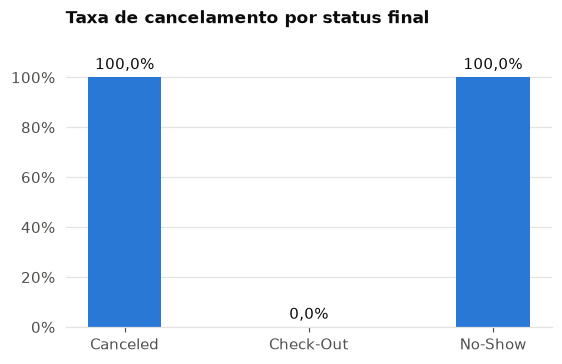

In [15]:
fig, ax = plt.subplots(figsize=(5, 3.2))
barras(ax, df.groupby("reservation_status")["is_canceled"].mean(), "Taxa de cancelamento por status final")
plt.show()

As duas são a própria resposta: `Canceled`/`No-Show` é sempre `is_canceled = 1`, e a data do status é a data do cancelamento ou a data de saída. **Saem.**

**`assigned_room_type`** — o quarto que o hóspede de fato recebeu. Comparamos o cancelamento quando ele é diferente do quarto reservado.

In [16]:
quarto_diferente = df["assigned_room_type"] != df["reserved_room_type"]
df.assign(quarto_diferente=quarto_diferente).groupby("quarto_diferente")["is_canceled"].agg(["mean", "size"]).round(3)

,mean,size
quarto_diferente,,
False,0.315,74224
True,0.047,12988


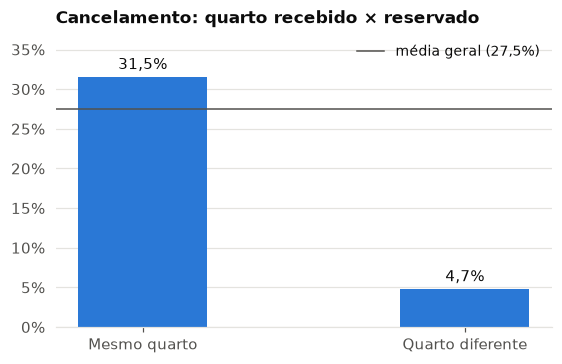

In [17]:
fig, ax = plt.subplots(figsize=(5, 3.2))
taxa = df.groupby(quarto_diferente)["is_canceled"].mean().rename({False: "Mesmo quarto", True: "Quarto diferente"})
barras(ax, taxa, "Cancelamento: quarto recebido × reservado", media=taxa_geral)
plt.show()

Quem recebeu quarto diferente cancela 5%, contra 32% dos demais. Não é que trocar de quarto evite cancelamento: o quarto é atribuído no check-in, então "quarto diferente" quase sempre significa que o hóspede apareceu. **Sai.**

**`booking_changes` e `days_in_waiting_list`** — alterações feitas na reserva e dias na lista de espera.

In [18]:
display(df.groupby(df["booking_changes"].clip(upper=3))["is_canceled"].agg(["mean", "size"]).round(3))
df.groupby(df["days_in_waiting_list"] > 0)["is_canceled"].agg(["mean", "size"]).round(3)

,mean,size
booking_changes,,
0,0.302,71413
1,0.139,10864
2,0.202,3481
3,0.166,1454


,mean,size
days_in_waiting_list,,
False,0.274,86357
True,0.344,855


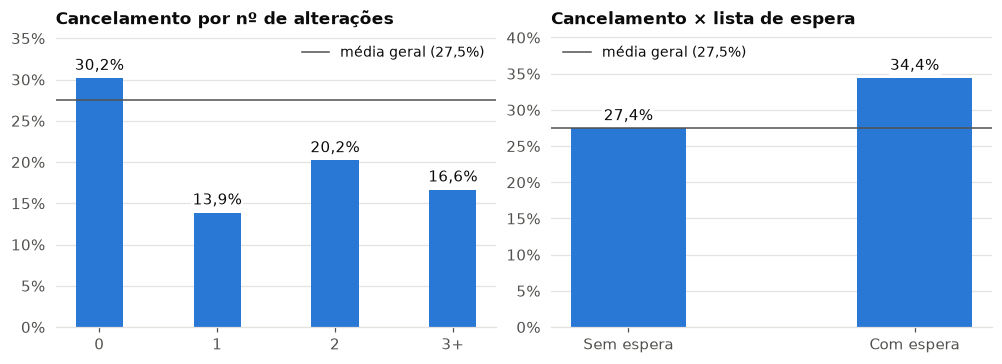

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
alteracoes = df.groupby(df["booking_changes"].clip(upper=3))["is_canceled"].mean().rename({3: "3+"})
barras(ax1, alteracoes, "Cancelamento por nº de alterações", media=taxa_geral)
espera = df.groupby(df["days_in_waiting_list"] > 0)["is_canceled"].mean().rename({False: "Sem espera", True: "Com espera"})
barras(ax2, espera, "Cancelamento × lista de espera", media=taxa_geral)
plt.show()

- `booking_changes` conta as alterações **até o check-in ou o cancelamento**. No dia da reserva ela é sempre 0; o valor final só existe depois. Reservas com alteração cancelam menos (14–20% contra 30%), em parte porque uma reserva que dura mais tem mais tempo para ser alterada. **Sai.**
- `days_in_waiting_list` conta os dias na lista de espera **antes** de a reserva ser confirmada. É conhecida no momento da confirmação, que é quando o modelo seria usado. Só 1% das reservas passou pela lista. **Fica.**

### 1.7 Auditoria de vazamento (parte 2)

`country`, `deposit_type` e duas colunas que apareceram na investigação: `required_car_parking_spaces` e `total_of_special_requests`.

**`country`** — Portugal (PRT) é o país mais comum. Comparamos a taxa de cancelamento de PRT com a dos demais, por segmento e por ano.

In [20]:
portugal = df["country"] == "PRT"
display(df.assign(portugal=portugal).groupby(["market_segment", "portugal"])["is_canceled"]
        .mean().unstack().round(3))

# entre canceladas e não canceladas, quanto é PRT em cada ano
df.assign(portugal=portugal).groupby(["arrival_date_year", "is_canceled"])["portugal"].mean().unstack().round(3)

portugal,False,True
market_segment,,
Aviation,0.078,0.361
Complementary,0.014,0.135
Corporate,0.029,0.149
Direct,0.107,0.192
Groups,0.016,0.583
Offline TA/TO,0.005,0.433
Online TA,0.332,0.435
Undefined,NaN,1.000


is_canceled,0,1
arrival_date_year,,
2015,0.390,0.958
2016,0.279,0.384
2017,0.222,0.286


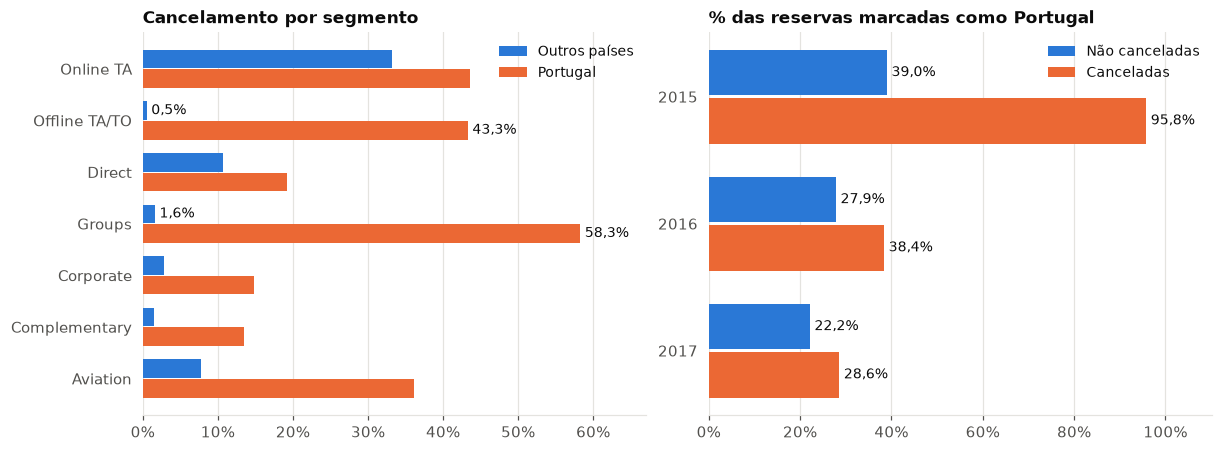

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

por_segmento = (df.assign(pais=portugal.map({False: "Outros países", True: "Portugal"}))
                .pivot_table(index="market_segment", columns="pais", values="is_canceled", aggfunc="mean"))
ordem = df["market_segment"].value_counts().index.drop("Undefined")
barras_agrupadas(ax1, por_segmento.loc[ordem], "Cancelamento por segmento", destacar=["Groups", "Offline TA/TO"])

por_ano = (df.assign(portugal=portugal).groupby(["arrival_date_year", "is_canceled"])["portugal"].mean()
           .unstack().rename(columns={0: "Não canceladas", 1: "Canceladas"}))
barras_agrupadas(ax2, por_ano, "% das reservas marcadas como Portugal", destacar=por_ano.index)
plt.show()

Os números não parecem comportamento real de hóspede:
- Em `Groups`, quem não é de Portugal cancela 1,6%, e quem é cancela 58%. Em `Offline TA/TO`, 0,5% contra 43%.
- Em 2015, **96% das reservas canceladas** estão como PRT, contra 39% das que fizeram check-out.

A explicação mais provável: o país só é confirmado no check-in. Quando a reserva cancela, fica o valor padrão (PRT). Ou seja, o país "sabe" se o hóspede apareceu. **Sai.**

**`deposit_type`** — por que as reservas `Non Refund` (depósito sem reembolso) cancelam tanto?

In [22]:
nao_reembolsavel = df[df["deposit_type"] == "Non Refund"]
print("Reservas Non Refund:", len(nao_reembolsavel), "| taxa de cancelamento:", round(nao_reembolsavel["is_canceled"].mean(), 3))
display(nao_reembolsavel["market_segment"].value_counts(normalize=True).round(3).head(3))

df.groupby(df["deposit_type"] == "Non Refund")[["lead_time", "total_of_special_requests", "previous_cancellations"]].mean().round(2)

Reservas Non Refund: 1037 | taxa de cancelamento: 0.947


market_segment
Groups           0.635
Offline TA/TO    0.276
Corporate        0.062
Name: proportion, dtype: float64

,lead_time,total_of_special_requests,previous_cancellations
deposit_type,,,
False,78.35,0.71,0.03
True,211.47,0.02,0.33


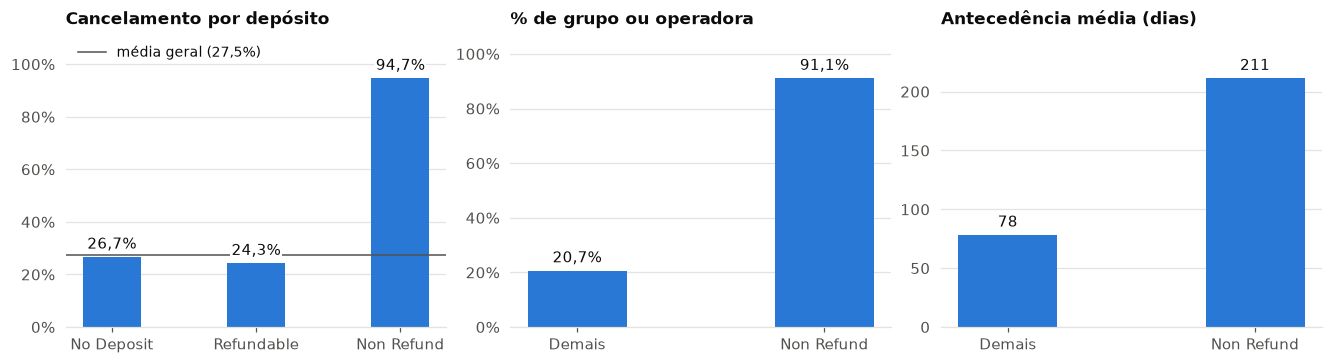

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
por_deposito = df.groupby("deposit_type")["is_canceled"].mean()[["No Deposit", "Refundable", "Non Refund"]]
barras(axes[0], por_deposito, "Cancelamento por depósito", media=taxa_geral)

tipo = (df["deposit_type"] == "Non Refund").map({False: "Demais", True: "Non Refund"})
grupo_ou_operadora = df["market_segment"].isin(["Groups", "Offline TA/TO"])
barras(axes[1], grupo_ou_operadora.groupby(tipo).mean(), "% de grupo ou operadora")
barras(axes[2], df.groupby(tipo)["lead_time"].mean(), "Antecedência média (dias)", formato=lambda v: f"{v:.0f}")
plt.show()

As `Non Refund` são 1,2% da base e têm outro perfil: 91% são de grupo ou operadora, feitas com muito mais antecedência (211 dias em média, contra 78), quase sem pedidos especiais e com mais cancelamentos anteriores. Parecem **bloqueios de quartos de grupos e operadoras**, que são cancelados quando não são preenchidos — e não clientes comuns que pagaram e desistiram.

O tipo de depósito é uma condição definida na reserva, então passa no teste do "já existia?". **Fica**, com a ressalva: na hora de explicar o modelo, `Non Refund` deve ser lido como "bloqueio de grupo", não como "depósito causa cancelamento".

**`required_car_parking_spaces` e `total_of_special_requests`** — vagas de estacionamento e pedidos especiais.

In [24]:
display(df.groupby(df["required_car_parking_spaces"] > 0)["is_canceled"].agg(["mean", "size"]).round(4))
df.groupby(df["total_of_special_requests"].clip(upper=3))["is_canceled"].agg(["mean", "size"]).round(3)

,mean,size
required_car_parking_spaces,,
False,0.3003,79906
True,0.0000,7306


,mean,size
total_of_special_requests,,
0,0.332,43773
1,0.224,28974
2,0.213,11795
3,0.162,2670


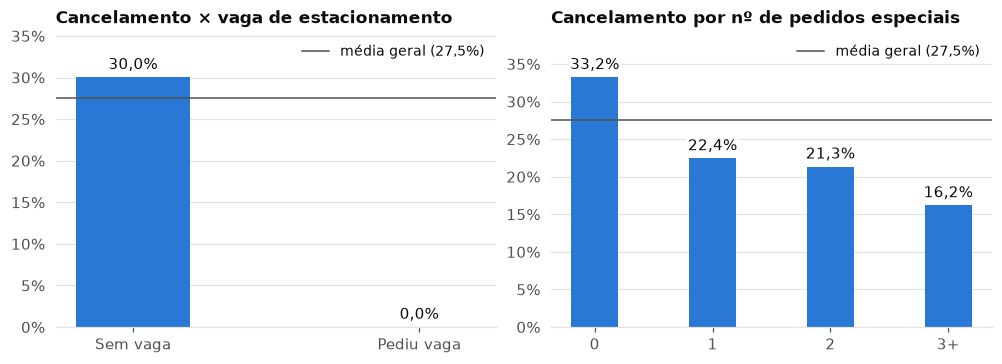

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
vaga = df.groupby(df["required_car_parking_spaces"] > 0)["is_canceled"].mean().rename({False: "Sem vaga", True: "Pediu vaga"})
barras(ax1, vaga, "Cancelamento × vaga de estacionamento", media=taxa_geral)
pedidos = df.groupby(df["total_of_special_requests"].clip(upper=3))["is_canceled"].mean().rename({3: "3+"})
barras(ax2, pedidos, "Cancelamento por nº de pedidos especiais", media=taxa_geral)
plt.show()

- `required_car_parking_spaces`: as 7.306 reservas com vaga pedida têm **exatamente 0%** de cancelamento, nos dois hotéis. Nenhum comportamento real dá zero absoluto; o mais provável é que a vaga seja registrada na chegada. **Sai.**
- `total_of_special_requests`: cancelamento cai aos poucos (33% sem pedido → 16% com 3 ou mais), sem zerar. Faz sentido: quem faz pedidos está mais comprometido com a viagem. **Fica** — mas pedidos feitos depois da reserva podem estar somados aqui, então é uma variável para olhar com atenção na explicação do modelo.

### 1.8 Decisão final das colunas e base limpa

Uma linha por coluna: se entra no modelo e por quê. A tabela também serve para escolher as colunas no código, então a decisão fica num lugar só.

In [26]:
decisoes = pd.DataFrame([
    ("is_canceled", "alvo", "o que queremos prever"),
    ("arrival_date", "auxiliar", "só para separar treino, validação e teste por data"),

    ("hotel", "usa", "conhecida na reserva"),
    ("lead_time", "usa", "conhecida na reserva"),
    ("arrival_date_month", "usa", "conhecida na reserva (sazonalidade)"),
    ("stays_in_weekend_nights", "usa", "conhecida na reserva"),
    ("stays_in_week_nights", "usa", "conhecida na reserva"),
    ("adults", "usa", "conhecida na reserva"),
    ("children", "usa", "conhecida na reserva"),
    ("babies", "usa", "conhecida na reserva"),
    ("meal", "usa", "conhecida na reserva"),
    ("market_segment", "usa", "conhecida na reserva"),
    ("distribution_channel", "usa", "conhecida na reserva"),
    ("is_repeated_guest", "usa", "histórico do cliente até a reserva"),
    ("previous_cancellations", "usa", "histórico do cliente até a reserva"),
    ("previous_bookings_not_canceled", "usa", "histórico do cliente até a reserva"),
    ("reserved_room_type", "usa", "conhecida na reserva"),
    ("deposit_type", "usa", "condição da reserva; Non Refund ≈ bloqueio de grupo"),
    ("agent", "usa", "conhecida na reserva"),
    ("company", "usa", "conhecida na reserva"),
    ("days_in_waiting_list", "usa", "conhecida na confirmação"),
    ("customer_type", "usa", "conhecida na reserva"),
    ("adr", "usa", "preço combinado na reserva"),
    ("total_of_special_requests", "usa", "pode somar pedidos feitos depois — olhar na explicação"),

    ("reservation_status", "vazamento", "é a própria resposta"),
    ("reservation_status_date", "vazamento", "data do cancelamento ou da saída"),
    ("assigned_room_type", "vazamento", "quarto definido no check-in"),
    ("booking_changes", "vazamento", "contada até o check-in ou o cancelamento"),
    ("country", "vazamento", "canceladas ficam com Portugal como padrão"),
    ("required_car_parking_spaces", "vazamento", "quem pediu vaga cancela exatamente 0%"),

    ("arrival_date_year", "não usa", "o modelo será usado em anos que não viu"),
    ("arrival_date_week_number", "não usa", "repete a informação do mês"),
    ("arrival_date_day_of_month", "não usa", "sem significado para o negócio"),
    ("guests", "não usa", "soma de adults, children e babies"),
    ("nights", "não usa", "soma das noites de semana e de fim de semana"),
], columns=["coluna", "decisão", "motivo"])

# garante que nenhuma coluna ficou sem decisão
assert set(decisoes["coluna"]) == set(df.columns)

display(decisoes["decisão"].value_counts())
decisoes

decisão
usa          22
vazamento     6
não usa       5
alvo          1
auxiliar      1
Name: count, dtype: int64

,coluna,decisão,motivo
0,is_canceled,alvo,o que queremos prever
1,arrival_date,auxiliar,"só para separar treino, validação e teste por ..."
2,hotel,usa,conhecida na reserva
3,lead_time,usa,conhecida na reserva
4,arrival_date_month,usa,conhecida na reserva (sazonalidade)
5,stays_in_weekend_nights,usa,conhecida na reserva
6,stays_in_week_nights,usa,conhecida na reserva
7,adults,usa,conhecida na reserva
8,children,usa,conhecida na reserva
9,babies,usa,conhecida na reserva


Fica a base só com as colunas do modelo, o alvo e a data de chegada, salva em `data/processed/` para o notebook de modelagem. O formato parquet guarda os tipos (texto, inteiro, data), que o CSV perderia.

In [27]:
manter = decisoes.loc[decisoes["decisão"].isin(["alvo", "auxiliar", "usa"]), "coluna"]
base_modelo = df[manter]

base_modelo.to_parquet("../data/processed/reservas.parquet", index=False)
print("Salvo:", base_modelo.shape[0], "reservas,", base_modelo.shape[1], "colunas")

Salvo: 87212 reservas, 24 colunas


## Etapa 2 — Análise exploratória

O que está ligado ao cancelamento? Só com as colunas que passaram na auditoria. Cada gráfico termina com a conclusão em uma frase.

### 2.1 Hotel e tempo

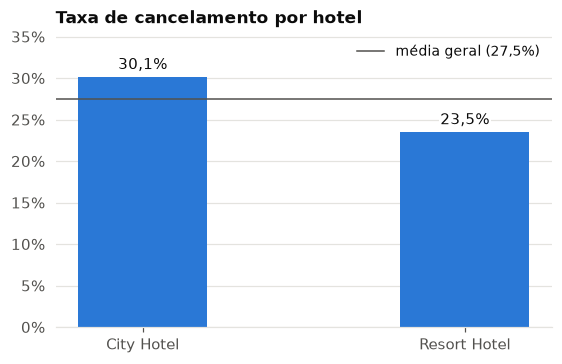

In [28]:
fig, ax = plt.subplots(figsize=(5, 3.2))
barras(ax, df.groupby("hotel")["is_canceled"].mean(), "Taxa de cancelamento por hotel", media=taxa_geral)
plt.show()

O City Hotel (Lisboa) cancela mais que o Resort (Algarve): 30% contra 24%.

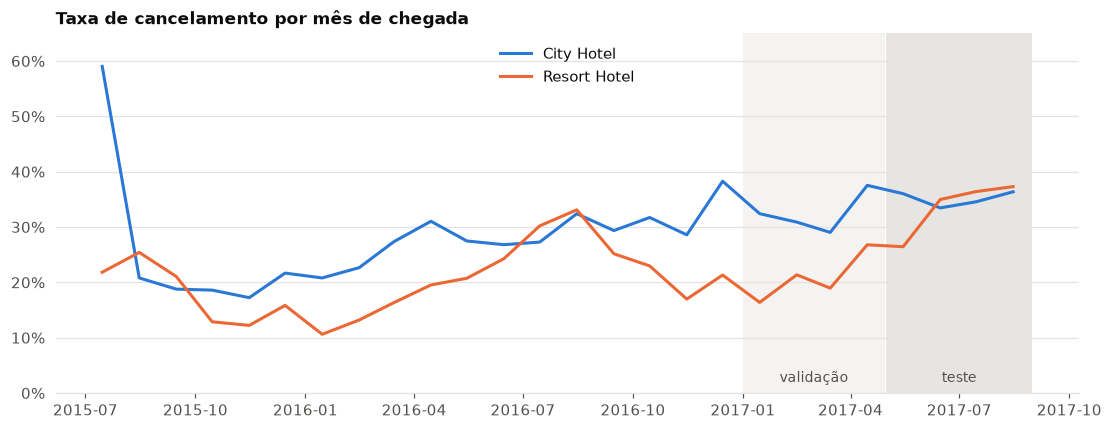

arrival_date
2015    0.203
2016    0.265
2017    0.319
Name: taxa de cancelamento, dtype: float64

In [29]:
# um ponto por mês de chegada, posicionado no meio do mês
meio_do_mes = df["arrival_date"].dt.to_period("M").dt.to_timestamp() + pd.Timedelta(days=14)
mensal = df.groupby([meio_do_mes, "hotel"])["is_canceled"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 3.8))
for hotel, cor in zip(mensal.columns, [AZUL, LARANJA]):
    ax.plot(mensal.index, mensal[hotel], color=cor, linewidth=2, label=hotel)

# períodos que vão ser validação e teste na modelagem
for inicio, fim, nome, opacidade in [("2017-01-01", "2017-04-30", "validação", 0.4), ("2017-05-01", "2017-08-31", "teste", 0.9)]:
    ax.axvspan(pd.Timestamp(inicio), pd.Timestamp(fim), color=GRADE, alpha=opacidade, linewidth=0)
    ax.text(pd.Timestamp(inicio) + (pd.Timestamp(fim) - pd.Timestamp(inicio)) / 2, 0.02, nome,
            ha="center", color=TEXTO_SECUNDARIO, fontsize=9)

ax.set_ylim(0, 0.65)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.legend(frameon=False, loc="upper center")
ax.set_title("Taxa de cancelamento por mês de chegada")
plt.show()

df.groupby(df["arrival_date"].dt.year)["is_canceled"].mean().round(3).rename("taxa de cancelamento")

- **O cancelamento sobe com o tempo:** 20% em 2015, 27% em 2016 e 32% em 2017, nos dois hotéis.
- **O Resort tem sazonalidade forte:** cancela mais no verão (30–37% em jun–ago) e bem menos no inverno (10–17%). O City Hotel varia menos ao longo do ano.
- O primeiro mês do City Hotel (jul/2015, 59%) destoa de todo o resto — provavelmente efeito do início da coleta dos dados.

**Por que isso importa para a modelagem:** o período de teste (mai–ago/2017) cancela ~35%, bem acima do que o modelo vai ver no treino (~25%). Um split aleatório misturaria os anos e esconderia essa mudança; o split por data mostra como o modelo se sai num futuro que ele não conhece — que é o uso real.

### 2.2 Antecedência, segmento e canal

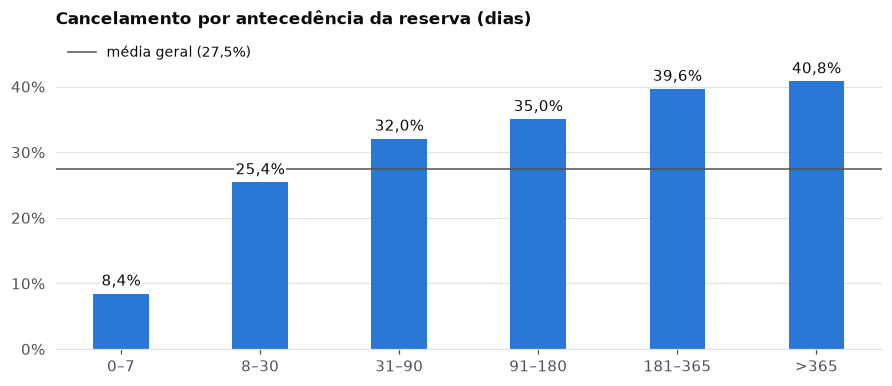

lead_time
0–7        18203
8–30       16325
31–90      22717
91–180     18224
181–365    11179
>365         564
Name: reservas, dtype: int64

In [30]:
faixas = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, df["lead_time"].max()],
                labels=["0–7", "8–30", "31–90", "91–180", "181–365", ">365"])

fig, ax = plt.subplots(figsize=(8, 3.4))
barras(ax, df.groupby(faixas, observed=True)["is_canceled"].mean(),
       "Cancelamento por antecedência da reserva (dias)", media=taxa_geral)
plt.show()

faixas.value_counts(sort=False).rename("reservas")

**Quanto mais cedo a reserva é feita, mais ela cancela:** 8% quando feita na última semana, 32% com 1 a 3 meses e 40% com mais de 6 meses. Faz sentido: há mais tempo para os planos mudarem. É o padrão mais claro da base.

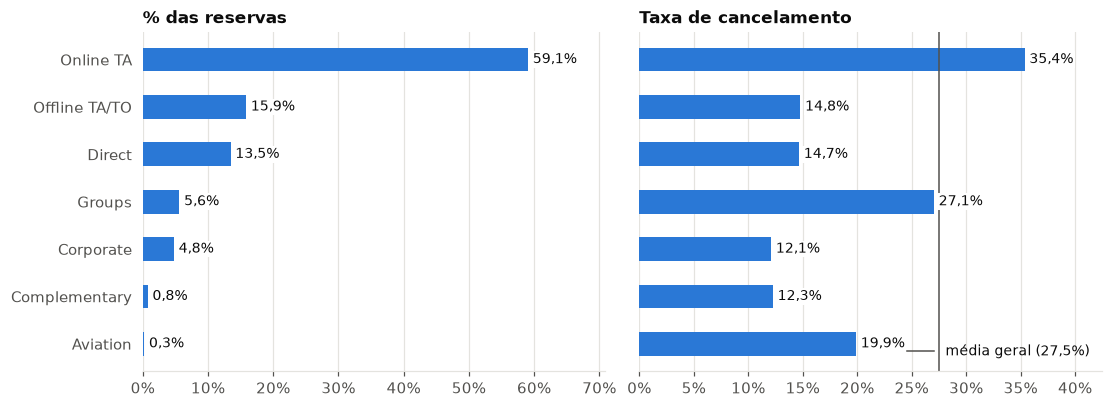

In [31]:
# sem o segmento "Undefined" (2 reservas)
segmentos = df[df["market_segment"] != "Undefined"]
ordem = segmentos["market_segment"].value_counts().index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
barras_horizontais(ax1, segmentos["market_segment"].value_counts(normalize=True)[ordem], "% das reservas")
barras_horizontais(ax2, segmentos.groupby("market_segment")["is_canceled"].mean()[ordem],
                   "Taxa de cancelamento", media=taxa_geral)
plt.show()

**Agências online (`Online TA`) são 59% das reservas e as que mais cancelam (35%).** Reserva direta, operadoras e empresas ficam entre 12% e 15%. Grupos, depois de tirar as duplicadas, cancelam 27% — perto da média.

**Canal de venda** — de onde vem cada segmento (proporção por linha).

In [32]:
pd.crosstab(segmentos["market_segment"], segmentos["distribution_channel"], normalize="index").loc[ordem].round(2)

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
market_segment,,,,,
Online TA,0.00,0.00,0.0,0.99,0.0
Offline TA/TO,0.01,0.00,0.0,0.99,0.0
Direct,0.01,0.97,0.0,0.02,0.0
Groups,0.14,0.13,0.0,0.73,0.0
Corporate,0.93,0.04,0.0,0.04,0.0
Complementary,0.11,0.78,0.0,0.11,0.0
Aviation,0.96,0.00,0.0,0.04,0.0


O canal quase repete o segmento: 99% das `Online TA` e das `Offline TA/TO` vêm pelo canal `TA/TO`, e 97% das `Direct` pelo canal `Direct`. As duas colunas ficam no modelo, mas o canal acrescenta pouca informação nova.